## A/B test: paid-first feed layout

Цель анализа — проверить, улучшает ли размещение платных элементов перед органическим контентом монетизацию ленты и не ухудшает ли пользовательскую вовлечённость.

Перед выполнением АБ теста были сформированы 7 гипотез и методом RICE выбраны 2 гипотезы - файл [prioritization_of_hypotheses_RICE_method.md](prioritization_of_hypotheses_RICE_method.md)
Оставляем только гипотезу N1.

### Продуктовая гипотеза

Если разместить четыре платных элемента перед органическим элементом, то Paid CTR, RPM и RPS увеличатся, поскольку пользователи раньше увидят рекламные объявления.
При этом необходимо проверить, не снизятся ли Organic CTR и количество просмотров страниц за сессию.

Гипотеза 1.1. RPM
**H0:** RPM в группах A и B статистически значимо не различается.
**H1:** RPM в группе B статистически значимо выше, чем в группе A.

Гипотеза 1.2. RPS
**H0:** RPS в группах A и B статистически значимо не различается.
**H1:** RPS в группе B статистически значимо выше, чем в группе A.

Гипотеза 1.3. Paid CTR
**H0:** Paid CTR в группах A и B статистически значимо не различается.
**H1:** Paid CTR в группе B статистически значимо выше, чем в группе A.

Гипотеза 1.4. Organic CTR
**H0:** Organic CTR в группах A и B статистически значимо не различается.
**H1:** Organic CTR в группе B статистически значимо ниже, чем в группе A.

Гипотеза 1.5. Количество просмотров страниц за сессию
**H0:** среднее количество просмотров страниц за сессию в группах A и B статистически значимо не различается.
**H1:** среднее количество просмотров страниц за сессию в группе B статистически значимо ниже, чем в группе A.

### Загрузка данных эксперимента, подготовка и проведение EDA (предварительный анализ данных).

In [91]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('csv/marketpele_ab_test_data_set.csv', sep=',')

In [92]:
df.dtypes

date                     str
publisher_id           int64
platform                 str
group_name               str
 pageviews               str
 visible_pageviews       str
 sessions                str
 revenue                 str
sponsord_clicks        int64
organic_clicks         int64
dtype: object

In [111]:
df.columns = df.columns.str.strip()
display(df.head(15))
display(df.dtypes)

,date,publisher_id,platform,group_name,pageviews,visible_pageviews,sessions,revenue,sponsord_clicks,organic_clicks
0,2019-03-01,101,Desktop,A,16580,5418,12684,34.52,300,849
1,2019-03-01,101,Desktop,B,16191,4906,12717,32.92,268,555
2,2019-03-01,106,Desktop,A,16227,11395,11750,20.16,601,2425
3,2019-03-01,106,Desktop,B,15060,10369,11967,19.74,663,1194
4,2019-03-01,106,Mobile,A,30494,7715,22843,82.93,456,1600
5,2019-03-01,106,Mobile,B,30079,7299,23103,100.82,517,672
6,2019-03-01,111,Desktop,A,12876,5028,8664,68.39,322,745
7,2019-03-01,111,Desktop,B,12135,4458,8524,59.55,278,271
8,2019-03-01,123,Desktop,A,26095,4409,19920,11.52,298,807
9,2019-03-01,123,Desktop,B,25546,4118,19915,11.59,320,402


date                     str
publisher_id           int64
platform                 str
group_name               str
pageviews              Int64
visible_pageviews      Int64
sessions               Int64
revenue              Float64
sponsord_clicks        int64
organic_clicks         int64
dtype: object

In [94]:
df['revenue'] = df['revenue'].str.replace('$', '', regex=False).str.replace(',', '.', regex=False)
df['revenue'] = df['revenue'].str.replace(r'\s+', '', regex=True).astype('Float64')

In [95]:
int_columns = ['pageviews', 'visible_pageviews', 'sessions']

for column in int_columns:
    df[column] = (
        df[column]
        .str.replace(r'\s+', '', regex=True)
        .astype('Int64')
    )

## Paired bootstrap для ratio-метрик

Метрики являются отношениями агрегированных величин, поэтому обычный t-test нельзя корректно применить напрямую.

Данные агрегированы по `date`, `publisher_id`, `platform` и `group_name`, поэтому A/B-строки нельзя пересэмплировать независимо.

Bootstrap-единица: `date + publisher_id + platform`.

Paired bootstrap многократно пересчитывает глобальную ratio-метрику, сохраняя matched-структуру A/B-блоков.

In [96]:
import numpy as np

def bootstrap_ratio_paired(
    a_numerator,
    a_denominator,
    b_numerator,
    b_denominator,
    n_bootstrap=10_000,
    multiplier=1):
    """
    Paired Poisson bootstrap для глобальной ratio-метрики.

    Важно:
    a_numerator[i], a_denominator[i],
    b_numerator[i], b_denominator[i]
    должны относиться к одному и тому же блоку:

    date + publisher_id + platform

    Пример:
    A: 2019-03-01 | 106 | Desktop
    B: 2019-03-01 | 106 | Desktop

    Один и тот же bootstrap-вес применяется к A и B внутри пары.
    """
    weights = np.random.poisson(1, size=(n_bootstrap, len(a_numerator)))
    global_a = (np.sum(weights * a_numerator, axis=1) / np.sum(weights * a_denominator, axis=1) * multiplier)
    global_b = (np.sum(weights * b_numerator, axis=1) / np.sum(weights * b_denominator, axis=1) * multiplier)

    return global_a, global_b

Функция `analyze_ratio_metric_by_platform()` универсальна для ratio-метрик: метрика задаётся через числитель, знаменатель и множитель.

На выходе получаем observed values для A/B, абсолютную и относительную разницу, bootstrap confidence bounds, стандартное отклонение bootstrap-распределения, количество matched-блоков и сами bootstrap samples для графиков.

In [97]:
def analyze_ratio_metric_by_platform(df, platform, numerator_col, denominator_col,  metric_name,  multiplier=1, n_bootstrap=10_000, alpha=0.05):
    """
    Анализ ratio-метрики с paired bootstrap.

    Если platform=None, считаем Overall по всем платформам.
    metric = sum(numerator) / sum(denominator) * multiplier
    Примеры:
    RPM = revenue / pageviews * 1000
    RPS = revenue / sessions * 1000
    Paid CTR = sponsord_clicks / visible_pageviews * 100
    Organic CTR = organic_clicks / visible_pageviews * 100
    Pages per Session = pageviews / sessions
    Bootstrap-единица всегда:
    date + publisher_id + platform
    Один и тот же bootstrap-вес применяется к A и B внутри одного блока.
    """

    if platform is None:
        df_platform = df.copy()
        platform_label = 'Overall'
    else:
        df_platform = df[df['platform'] == platform].copy()
        platform_label = platform

    block_cols = ['date', 'publisher_id', 'platform']
    block_data = (df_platform.groupby(block_cols + ['group_name'], as_index=False) .agg(numerator=(numerator_col, 'sum'),denominator=(denominator_col, 'sum')))
    wide = block_data.pivot_table(index=block_cols, columns='group_name', values=['numerator', 'denominator'], aggfunc='sum')
    a_numerator = wide[('numerator', 'A')].to_numpy()
    a_denominator = wide[('denominator', 'A')].to_numpy()
    b_numerator = wide[('numerator', 'B')].to_numpy()
    b_denominator = wide[('denominator', 'B')].to_numpy()
    metric_a = (a_numerator.sum()/ a_denominator.sum() * multiplier)
    metric_b = (b_numerator.sum() / b_denominator.sum() * multiplier)
    absolute_difference = metric_b - metric_a
    relative_difference_pct = (metric_b / metric_a - 1) * 100
    bootstrap_metric_a, bootstrap_metric_b = bootstrap_ratio_paired(a_numerator=a_numerator, a_denominator=a_denominator, b_numerator=b_numerator, b_denominator=b_denominator,
        n_bootstrap=n_bootstrap, multiplier=multiplier)
    bootstrap_difference = bootstrap_metric_b - bootstrap_metric_a
    bootstrap_relative_difference_pct = (bootstrap_metric_b / bootstrap_metric_a - 1) * 100
    lower_bound = np.quantile(bootstrap_difference, alpha)
    upper_bound = np.quantile(bootstrap_difference, 1 - alpha)

    relative_difference_lower_pct = np.quantile(bootstrap_relative_difference_pct, alpha)
    relative_difference_upper_pct = np.quantile(bootstrap_relative_difference_pct, 1 - alpha)

    return {
        # scalar results for summary table
        'metric': metric_name,
        'platform': platform_label,

        'metric_a': metric_a,
        'metric_b': metric_b,

        'absolute_difference': absolute_difference,
        'relative_difference_pct': relative_difference_pct,

        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'ci_width': upper_bound - lower_bound,
        'bootstrap_diff_std': np.std(bootstrap_difference),

        'relative_difference_lower_pct': relative_difference_lower_pct,
        'relative_difference_upper_pct': relative_difference_upper_pct,
        'relative_difference_ci_width_pct': (relative_difference_upper_pct - relative_difference_lower_pct),
        'bootstrap_relative_difference_std_pct': np.std(bootstrap_relative_difference_pct),
        'n_blocks': len(wide),

        # arrays for plots
        'bootstrap_metric_a': bootstrap_metric_a,
        'bootstrap_metric_b': bootstrap_metric_b,
        'bootstrap_difference': bootstrap_difference,
        'bootstrap_relative_difference_pct': bootstrap_relative_difference_pct
    }

## Расчёт overall-метрик

На этом этапе рассчитываются все overall-метрики по всем платформам вместе.  
Детальная интерпретация каждой метрики приведена ниже в отдельных секциях.

In [98]:
np.random.seed(42)

rpm_overall = analyze_ratio_metric_by_platform(
    df=df,
    platform=None,
    numerator_col='revenue',
    denominator_col='pageviews',
    metric_name='RPM',
    multiplier=1000,
    n_bootstrap=10_000,
    alpha=0.05
)

rps_overall = analyze_ratio_metric_by_platform(
    df=df,
    platform=None,
    numerator_col='revenue',
    denominator_col='sessions',
    metric_name='RPS',
    multiplier=1000,
    n_bootstrap=10_000,
    alpha=0.05
)

paid_ctr_overall = analyze_ratio_metric_by_platform(
    df=df,
    platform=None,
    numerator_col='sponsord_clicks',
    denominator_col='visible_pageviews',
    metric_name='Paid CTR',
    multiplier=100,
    n_bootstrap=10_000,
    alpha=0.05
)

organic_ctr_overall = analyze_ratio_metric_by_platform(
    df=df,
    platform=None,
    numerator_col='organic_clicks',
    denominator_col='visible_pageviews',
    metric_name='Organic CTR',
    multiplier=100,
    n_bootstrap=10_000,
    alpha=0.05
)

pps_overall = analyze_ratio_metric_by_platform(
    df=df,
    platform=None,
    numerator_col='pageviews',
    denominator_col='sessions',
    metric_name='Pages per Session',
    multiplier=1,
    n_bootstrap=10_000,
    alpha=0.05
)

### Гипотеза 1.1. RPM / RPS

**H0:** RPM / RPS в группах A и B статистически значимо не различается.
**H1:** RPM / RPS в группе B статистически значимо выше, чем в группе A.

### Bootstrap-распределения RPM и RPS

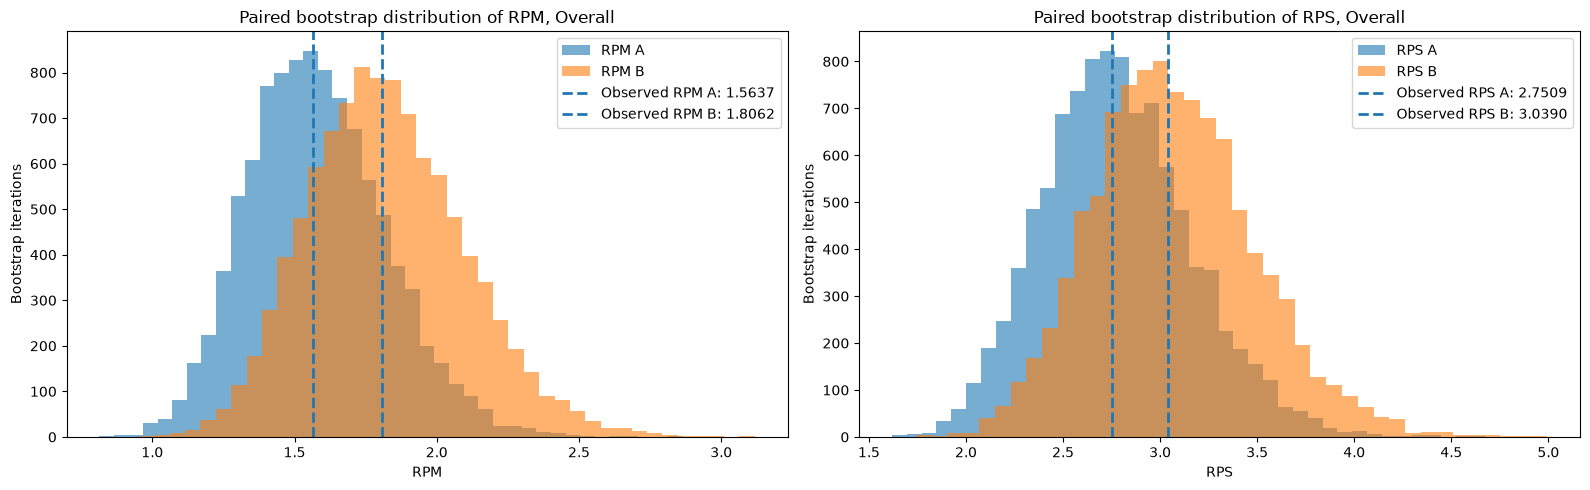

In [99]:
import matplotlib.pyplot as plt

def draw_metric_bootstrap_distribution(ax, result, bins=40):
    """
    Рисует один график bootstrap-распределения метрики A и B
    на переданной оси ax.
    """

    metric_name = result['metric']

    ax.hist(result['bootstrap_metric_a'], bins=bins,alpha=0.6,label=f'{metric_name} A')
    ax.hist(result['bootstrap_metric_b'], bins=bins, alpha=0.6,label=f'{metric_name} B')
    ax.axvline(result['metric_a'], linestyle='--', linewidth=2, label=f'Observed {metric_name} A: {result["metric_a"]:.4f}')
    ax.axvline(result['metric_b'], linestyle='--', linewidth=2, label=f'Observed {metric_name} B: {result["metric_b"]:.4f}')
    ax.set_title(f'Paired bootstrap distribution of {metric_name}, Overall')
    ax.set_xlabel(metric_name)
    ax.set_ylabel('Bootstrap iterations')
    ax.legend()
def plot_metric_bootstrap_distributions_side_by_side(result_left, result_right,bins=40, save_path_left=None,save_path_right=None):
    """
    Показываем два bootstrap-графика рядом, но сохраняем каждый график отдельным SVG-файлом.
    """
    # -------------------------
    # Показываем два графика рядом
    # -------------------------
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))
    draw_metric_bootstrap_distribution(ax=axes[0], result=result_left, bins=bins)
    draw_metric_bootstrap_distribution(ax=axes[1], result=result_right, bins=bins)
    fig.tight_layout()
    plt.show()

    # -------------------------
    # Сохраняем левый график отдельно
    # -------------------------

    if save_path_left is not None:
        fig_left, ax_left = plt.subplots(figsize=(8, 5))
        draw_metric_bootstrap_distribution(ax=ax_left, result=result_left,  bins=bins)
        fig_left.tight_layout()
        fig_left.savefig(save_path_left, format='svg', bbox_inches='tight')
        plt.close(fig_left)

    # -------------------------
    # Сохраняем правый график отдельно
    # -------------------------
    if save_path_right is not None:
        fig_right, ax_right = plt.subplots(figsize=(8, 5))
        draw_metric_bootstrap_distribution(ax=ax_right,result=result_right, bins=bins)
        fig_right.tight_layout()
        fig_right.savefig( save_path_right,  format='svg', bbox_inches='tight')
        plt.close(fig_right)

plot_metric_bootstrap_distributions_side_by_side(result_left=rpm_overall, result_right=rps_overall, save_path_left='svg/paired_bootstrap_distribution_rpm_overall.svg',
    save_path_right='svg/paired_bootstrap_distribution_rps_overall.svg')

### Относительное изменение RPM и RPS

`relative difference = (B / A - 1) × 100`

Для RPM и RPS проверяем направленную гипотезу о росте метрики в группе B.  
Поэтому используем нижнюю границу одностороннего 95% bootstrap confidence interval.

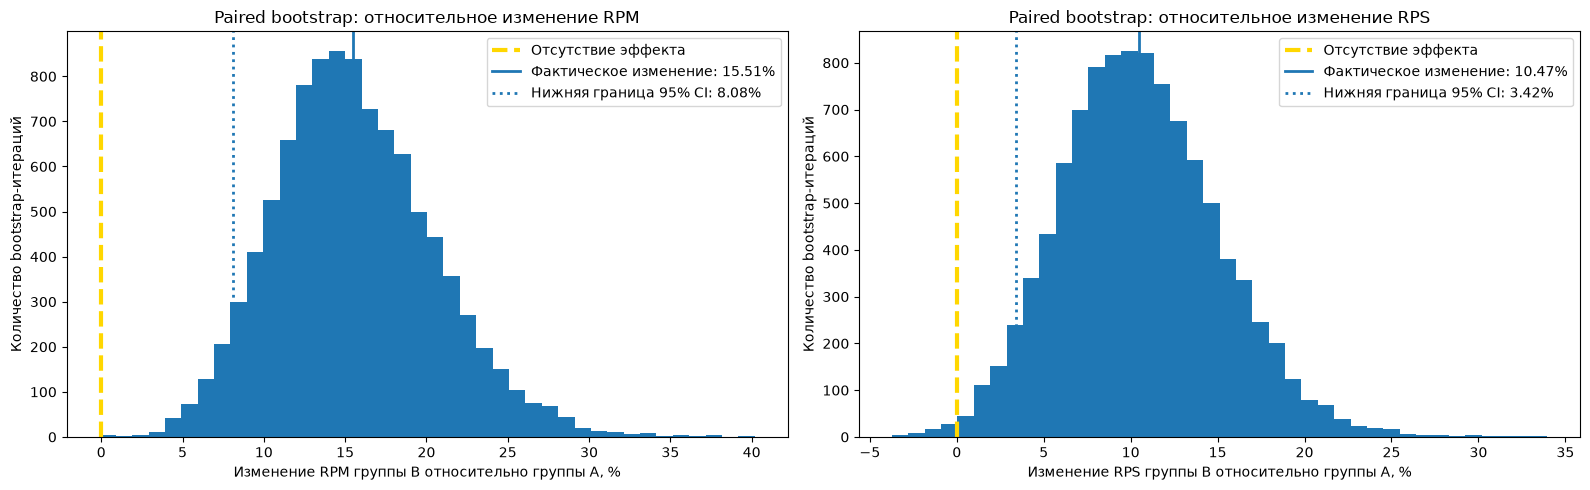

In [100]:
import matplotlib.pyplot as plt


def draw_relative_difference_bootstrap(
    ax,
    result,
    direction='increase',
    bins=40
):
    """
    Рисует bootstrap-распределение относительного изменения B относительно A.

    direction:
    - 'increase': проверяем рост B > A, используем нижнюю границу CI
    - 'decrease': проверяем снижение B < A, используем верхнюю границу CI
    """
    metric_name = result['metric']
    bootstrap_relative_difference = result['bootstrap_relative_difference_pct']
    observed_relative_difference = result['relative_difference_pct']
    if direction == 'increase':
        ci_bound = result['relative_difference_lower_pct']
        ci_label = 'Нижняя граница 95% CI'
    elif direction == 'decrease':
        ci_bound = result['relative_difference_upper_pct']
        ci_label = 'Верхняя граница 95% CI'
    else:
        raise ValueError("direction must be either 'increase' or 'decrease'")
    ax.hist(bootstrap_relative_difference, bins=bins)
    ax.axvline(0, color='gold',linewidth=3, linestyle='--',label='Отсутствие эффекта')
    ax.axvline( observed_relative_difference, linestyle='-',linewidth=2,label=f'Фактическое изменение: {observed_relative_difference:.2f}%')
    ax.axvline(ci_bound,linestyle=':',linewidth=2,label=f'{ci_label}: {ci_bound:.2f}%')
    ax.set_xlabel(f'Изменение {metric_name} группы B относительно группы A, %')
    ax.set_ylabel('Количество bootstrap-итераций')
    ax.set_title(f'Paired bootstrap: относительное изменение {metric_name}')
    ax.legend()

def show_relative_difference_side_by_side(result_left,result_right,direction_left='increase',direction_right='increase',bins=40):
    """
    Показывает два графика относительного изменения рядом.
    """
    fig, axes = plt.subplots( nrows=1,  ncols=2, figsize=(16, 5))
    draw_relative_difference_bootstrap(ax=axes[0], result=result_left, direction=direction_left, bins=bins)
    draw_relative_difference_bootstrap( ax=axes[1], result=result_right, direction=direction_right, bins=bins)

    fig.tight_layout()
    plt.show()

def save_relative_difference_bootstrap(result,save_path, direction='increase', bins=40):
    """
    Сохраняет один график относительного изменения отдельным SVG-файлом.
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    draw_relative_difference_bootstrap( ax=ax, result=result, direction=direction, bins=bins)
    fig.tight_layout()
    fig.savefig( save_path, format='svg', bbox_inches='tight')
    plt.close(fig)

show_relative_difference_side_by_side(result_left=rpm_overall, result_right=rps_overall, direction_left='increase', direction_right='increase')
save_relative_difference_bootstrap( result=rpm_overall, save_path='svg/paired_bootstrap_relative_difference_rpm_overall.svg', direction='increase')
save_relative_difference_bootstrap(result=rps_overall, save_path='svg/paired_bootstrap_relative_difference_rps_overall.svg',direction='increase')

In [101]:
def print_increase_conclusion( result, metric_label, value_suffix='', diff_suffix=''):
    lower_bound = result['lower_bound']
    fraction_positive = (result['bootstrap_difference'] > 0).mean()
    print(f'{metric_label} группы A: {result["metric_a"]:.4f}{value_suffix}')
    print(f'{metric_label} группы B: {result["metric_b"]:.4f}{value_suffix}')
    print(f'Абсолютная разница B − A: {result["absolute_difference"]:.4f}{diff_suffix}')
    print(f'Относительное изменение: {result["relative_difference_pct"]:.2f}%')
    print( f'Нижняя граница одностороннего 95% доверительного интервала разницы: 'f'{lower_bound:.4f}{diff_suffix}')
    print( f'Доля bootstrap-оценок, в которых {metric_label} группы B выше: {fraction_positive:.2%}')
    if lower_bound > 0:
        print(f'Отклоняем H0. {metric_label} в группе B статистически значимо выше, чем в группе A.\n')
    else:
        print(f'Недостаточно оснований отклонить H0. Статистически значимый рост {metric_label} не подтверждён.')
print_increase_conclusion(result=rpm_overall,  metric_label='RPM')
print_increase_conclusion(result=rps_overall,   metric_label='RPS')

RPM группы A: 1.5637
RPM группы B: 1.8062
Абсолютная разница B − A: 0.2425
Относительное изменение: 15.51%
Нижняя граница одностороннего 95% доверительного интервала разницы: 0.1226
Доля bootstrap-оценок, в которых RPM группы B выше: 99.97%
Отклоняем H0. RPM в группе B статистически значимо выше, чем в группе A.

RPS группы A: 2.7509
RPS группы B: 3.0390
Абсолютная разница B − A: 0.2881
Относительное изменение: 10.47%
Нижняя граница одностороннего 95% доверительного интервала разницы: 0.0971
Доля bootstrap-оценок, в которых RPS группы B выше: 99.43%
Отклоняем H0. RPS в группе B статистически значимо выше, чем в группе A.



### Гипотеза 1.2. Paid CTR

**H0:** Paid CTR в группах A и B статистически значимо не различается.
**H1:** Paid CTR в группе B статистически значимо выше, чем в группе A.

Visible Paid CTR = (sponsored clicks / visible pageviews)

Здесь считаю нужным уточнить, что метрику будем считать отностельно просмотренных польщователем страниц. Поэтому вопрос:
как часто пользователь кликает по рекламе при условии, что он действительно увидел ленту?

Необходимо проверить статистическую значимость наблюдаемого роста методом bootstrap.

In [102]:
print('\nVisible Paid CTR:')
print_increase_conclusion(result=paid_ctr_overall, metric_label='Visible Paid CTR', value_suffix='%', diff_suffix=' п.п.')


Visible Paid CTR:
Visible Paid CTR группы A: 6.0197%
Visible Paid CTR группы B: 7.3527%
Абсолютная разница B − A: 1.3330 п.п.
Относительное изменение: 22.14%
Нижняя граница одностороннего 95% доверительного интервала разницы: 1.0657 п.п.
Доля bootstrap-оценок, в которых Visible Paid CTR группы B выше: 100.00%
Отклоняем H0. Visible Paid CTR в группе B статистически значимо выше, чем в группе A.



### Гипотеза 1.3. Organic CTR

**H0:** Organic CTR в группах A и B статистически значимо не различается.
**H1:** Organic CTR в группе B статистически значимо ниже, чем в группе A.

Organic Visible CTR = (organic clicks / visible pageviews)

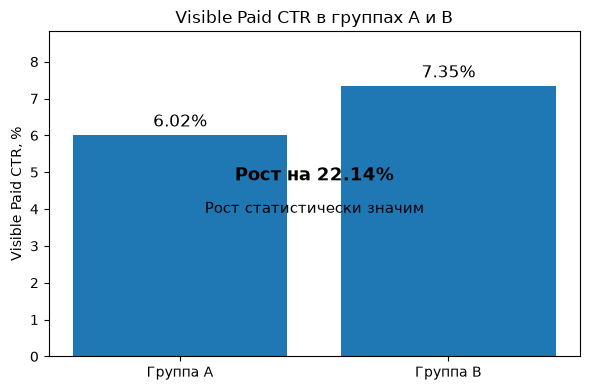

In [103]:
import os
import matplotlib.pyplot as plt

os.makedirs('svg', exist_ok=True)

result = paid_ctr_overall
values = [result['metric_a'], result['metric_b']]
groups = ['Группа A', 'Группа B']
relative_change = result['relative_difference_pct']
is_significant = result['lower_bound'] > 0
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(groups, values)
ax.bar_label(bars,  labels=[f'{value:.2f}%' for value in values],  padding=3, fontsize=12)
ax.text( 0.5, max(values) * 0.65, f'Рост на {relative_change:.2f}%', ha='center',fontsize=13, fontweight='bold')
ax.text(0.5, max(values) * 0.53, 'Рост статистически значим' if is_significant else 'Рост не подтверждён', ha='center', fontsize=11)
ax.set_ylabel('Visible Paid CTR, %')
ax.set_title('Visible Paid CTR в группах A и B')
ax.set_ylim(0, max(values) * 1.2)
fig.tight_layout()
fig.savefig('svg/visible_paid_ctr.svg',  format='svg', bbox_inches='tight')
plt.show()

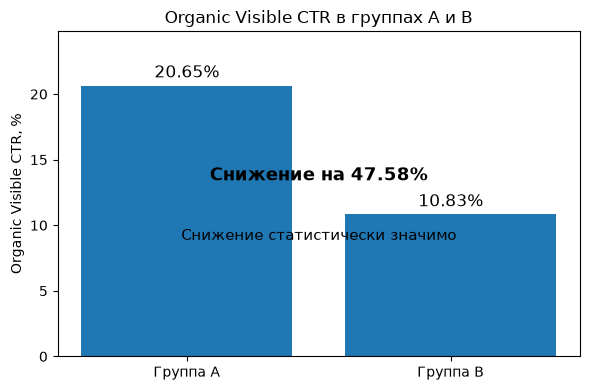

In [104]:
import os
import matplotlib.pyplot as plt

os.makedirs('svg', exist_ok=True)
result = organic_ctr_overall
values = [result['metric_a'], result['metric_b']]
groups = ['Группа A', 'Группа B']
relative_change = result['relative_difference_pct']
is_significant = result['upper_bound'] < 0
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(groups, values)
ax.bar_label( bars, labels=[f'{value:.2f}%' for value in values], padding=3, fontsize=12)
ax.text( 0.5,  max(values) * 0.65, f'Снижение на {abs(relative_change):.2f}%',  ha='center', fontsize=13, fontweight='bold')
ax.text( 0.5,  max(values) * 0.43,'Снижение статистически значимо' if is_significant else 'Снижение не подтверждено',  ha='center', fontsize=11)
ax.set_ylabel('Organic Visible CTR, %')
ax.set_title('Organic Visible CTR в группах A и B')
ax.set_ylim(0, max(values) * 1.2)
fig.tight_layout()
fig.savefig('svg/organic_visible_ctr.svg', format='svg', bbox_inches='tight')
plt.show()

In [105]:
def print_decrease_conclusion(result, metric_label, value_suffix='', diff_suffix=''):
    metric_a = result['metric_a']
    metric_b = result['metric_b']
    absolute_difference = result['absolute_difference']
    relative_difference = result['relative_difference_pct']
    upper_bound = result['upper_bound']
    relative_upper_bound = result['relative_difference_upper_pct']
    fraction_negative = (result['bootstrap_difference'] < 0).mean()
    print(f'{metric_label} группы A: {metric_a:.4f}{value_suffix}')
    print(f'{metric_label} группы B: {metric_b:.4f}{value_suffix}')
    print(f'Абсолютная разница B − A: {absolute_difference:.4f}{diff_suffix}')
    print(f'Относительное изменение: {relative_difference:.2f}%')
    print(f'Верхняя граница одностороннего 95% доверительного интервала разницы: {upper_bound:.4f}{diff_suffix}')
    print(f'Верхняя граница одностороннего 95% доверительного интервала относительного изменения: {relative_upper_bound:.2f}%')
    print(f'Доля bootstrap-оценок, в которых {metric_label} группы B ниже: {fraction_negative:.2%}')
    if upper_bound < 0:
        print(f'Отклоняем H0. {metric_label} в группе B статистически значимо ниже, чем в группе A.')
    else:
        print(f'Недостаточно оснований отклонить H0. Статистически значимое снижение {metric_label} не подтверждено.')

print_decrease_conclusion(
    result=organic_ctr_overall,
    metric_label='Organic Visible CTR',
    value_suffix='%',
    diff_suffix=' п.п.'
)

Organic Visible CTR группы A: 20.6512%
Organic Visible CTR группы B: 10.8259%
Абсолютная разница B − A: -9.8253 п.п.
Относительное изменение: -47.58%
Верхняя граница одностороннего 95% доверительного интервала разницы: -9.3673 п.п.
Верхняя граница одностороннего 95% доверительного интервала относительного изменения: -45.42%
Доля bootstrap-оценок, в которых Organic Visible CTR группы B ниже: 100.00%
Отклоняем H0. Organic Visible CTR в группе B статистически значимо ниже, чем в группе A.


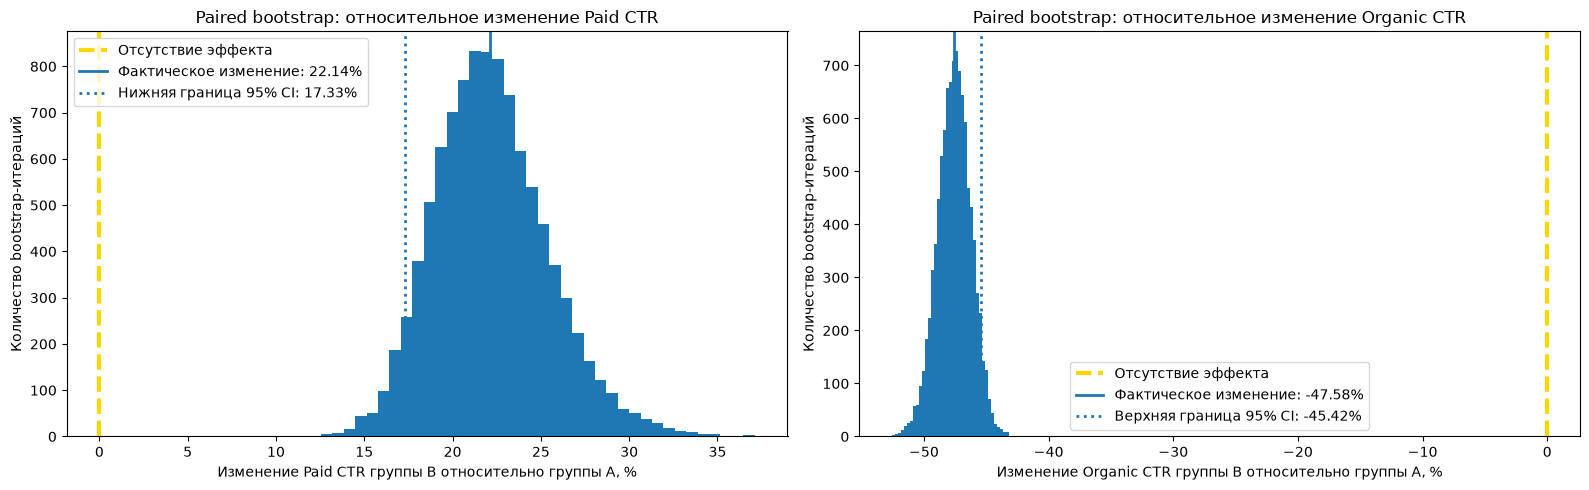

In [106]:
show_relative_difference_side_by_side(result_left=paid_ctr_overall, result_right=organic_ctr_overall, direction_left='increase',  direction_right='decrease')
save_relative_difference_bootstrap(result=paid_ctr_overall,save_path='svg/paired_bootstrap_relative_difference_paid_ctr_overall.svg', direction='increase')
save_relative_difference_bootstrap( result=organic_ctr_overall, save_path='svg/paired_bootstrap_relative_difference_organic_ctr_overall.svg', direction='decrease')

### Гипотеза 1.4. Количество просмотров страниц за сессию

**H0:** среднее количество просмотров страниц за сессию в группах A и B статистически значимо не различается.
**H1:** среднее количество просмотров страниц за сессию в группе B статистически значимо ниже, чем в группе A.

pageviews per session = (pageviews / sessions)

In [107]:
print('\nPages per Session:')
print_decrease_conclusion(
    result=pps_overall,
    metric_label='Pages per Session'
)


Pages per Session:
Pages per Session группы A: 1.7592
Pages per Session группы B: 1.6825
Абсолютная разница B − A: -0.0767
Относительное изменение: -4.36%
Верхняя граница одностороннего 95% доверительного интервала разницы: -0.0513
Верхняя граница одностороннего 95% доверительного интервала относительного изменения: -3.01%
Доля bootstrap-оценок, в которых Pages per Session группы B ниже: 100.00%
Отклоняем H0. Pages per Session в группе B статистически значимо ниже, чем в группе A.


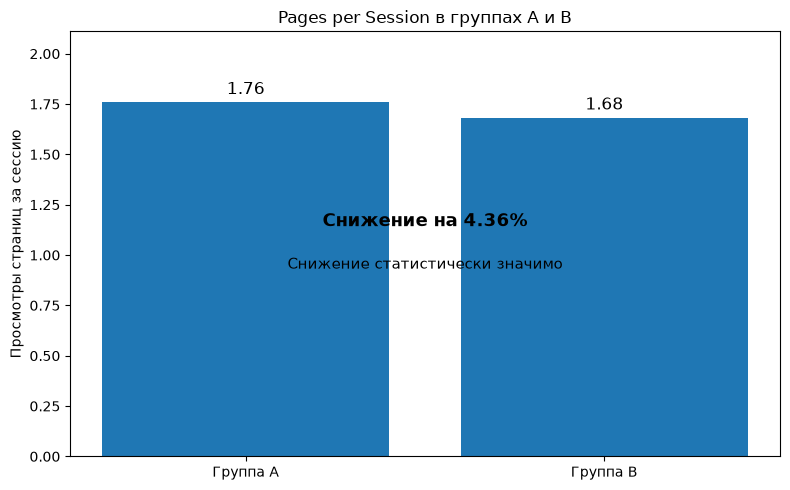

In [108]:
import os
import matplotlib.pyplot as plt

os.makedirs('svg', exist_ok=True)

result = pps_overall
values = [result['metric_a'], result['metric_b']]
groups = ['Группа A', 'Группа B']
relative_change = result['relative_difference_pct']
is_significant = result['upper_bound'] < 0
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(groups, values)
ax.bar_label( bars, labels=[f'{value:.2f}' for value in values],  padding=3, fontsize=12)
ax.text( 0.5, max(values) * 0.65, f'Снижение на {abs(relative_change):.2f}%',  ha='center', fontsize=13, fontweight='bold')
ax.text( 0.5,  max(values) * 0.53, 'Снижение статистически значимо' if is_significant else 'Снижение не подтверждено', ha='center', fontsize=11)
ax.set_ylabel('Просмотры страниц за сессию')
ax.set_title('Pages per Session в группах A и B')
ax.set_ylim(0, max(values) * 1.2)
fig.tight_layout()
fig.savefig('svg/pageviews_per_session.svg',  format='svg', bbox_inches='tight')
plt.show()

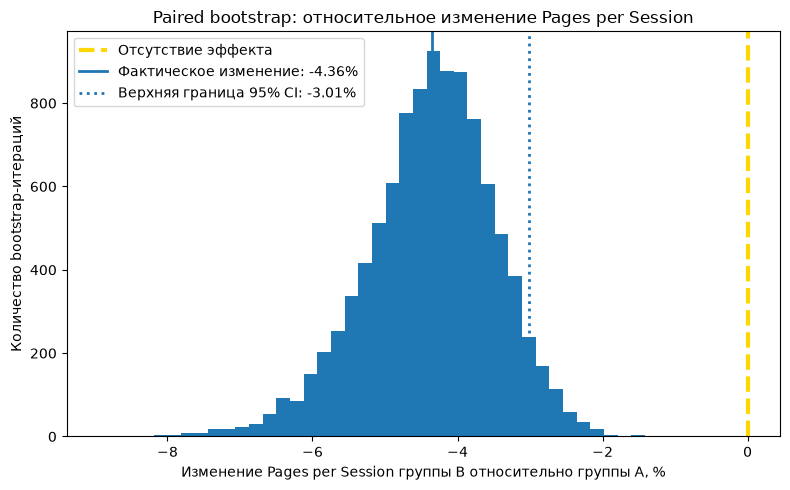

In [109]:
fig, ax = plt.subplots(figsize=(8, 5))
draw_relative_difference_bootstrap(ax=ax, result=pps_overall, direction='decrease')
fig.tight_layout()
fig.savefig('svg/paired_bootstrap_relative_difference_pps_overall.svg', format='svg',  bbox_inches='tight')
plt.show()

### Overall conclusion

Группа B показывает статистически значимый рост монетизационных метрик: RPM, RPS и Visible Paid CTR.
Однако guardrail-метрики ухудшились: Organic Visible CTR и Pages per Session статистически значимо снизились.
Итоговое решение о rollout зависит от бизнес-приоритета: если цель — максимизация рекламной монетизации, вариант B выглядит сильнее; если важно сохранить органическое взаимодействие и глубину сессии, изменение требует дополнительной проверки или более мягкого варианта.